# BigEarthNet-S2 — PALT training

Standalone full PALT training with 12 Sentinel-2 bands, official train/validation/test splits, and 19 multilabel classes. The provided Google Drive ZIP is downloaded and extracted automatically. Default: 30 epochs, early stopping, and seeds `[13,42,73]`. Select the classification threshold on validation only, then test with that fixed threshold. **Baseline comparisons are in notebook 3.** Only the selected dataset archive is downloaded.

The original PALT architecture is preserved: 4 transformer blocks, dimension 384, 6 heads, 32 prototypes, liquid dynamics, feedback, and PIH. It has no basis-expansion parameter. Models train from scratch. Data and splits live under `/kaggle/working/palt_data`; sorted archive paths and a fixed seed reproduce the same EuroSAT splits across Kaggle sessions. Each notebook writes to its own result directory.

**Kaggle:** enable Internet and select a GPU in Notebook Settings. Run cells in order. Results are saved under `/kaggle/working/PALT_TGRS_results`. Download them or use Save Version → Save & Run All to preserve outputs. The ZIP URL and extraction paths are editable below. The archives were not accessible for inspection during editing; supported layouts are checked at runtime.


## Training stability correction
FP32 training is enabled by default (`CFG.amp=False`) while retaining CUDA and the original model. This avoids FP16-specific overflows but does not guarantee all numerical failures are resolved. If AMP is explicitly enabled, non-finite gradients are detected before clipping, GradScaler skips that update and reduces its scale, and every skipped batch is logged. Ten overflows in one epoch stop the run. Strict checks remain active for FP32 failures. History is saved each epoch.

This version starts a fresh training run; it does not resume previous optimizer/scheduler state. Preserve earlier best.pt files before rerunning if needed. Apply the same precision setting to every compared model. Missing-positive-class AP warnings reflect subset label coverage, not a GPU error.

Validation of this correction: all code cells compiled and model-definition ASTs compared unchanged. No T4 execution was available for validation.


## Imagery-only archive fix
Your ZIP lacks labels. This version downloads official v2 metadata and matches patch IDs. Default `BEN_COVERAGE_MODE="available"` runs on the archive subset using official split assignments; it does not generate new splits. Coverage and subset status are saved in results. Empty official splits stop with an actionable error. Existing ZIP/extracted images are reused.


In [14]:
EXECUTION_MODE = "bigearthnet"  # Full official-split PALT experiment
SEEDS = [13, 42, 73]  # Optional: [13, 42, 73, 101, 202]
assert EXECUTION_MODE in {"bigearthnet"}
import importlib.util, subprocess, sys
# Preserve Kaggle's matched PyTorch/torchvision CUDA installation.
for module in ["torch","torchvision"]:
    if importlib.util.find_spec(module) is None:
        raise RuntimeError("Use a Kaggle Python GPU notebook with its bundled PyTorch/torchvision runtime.")
requirements={"gdown":"gdown>=5.2", "rasterio":"rasterio", "pyarrow":"pyarrow", "sklearn":"scikit-learn", "scipy":"scipy", "pandas":"pandas", "matplotlib":"matplotlib", "tqdm":"tqdm"}
missing=[package for module,package in requirements.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,"-m","pip","install","--quiet",*missing])
print("Kaggle dependencies ready; execution mode:", EXECUTION_MODE)


Kaggle dependencies ready; execution mode: bigearthnet


In [15]:
import gc, hashlib, inspect, json, math, os, random, time, warnings
from dataclasses import dataclass, asdict
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import models, transforms as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, confusion_matrix, classification_report, average_precision_score,
    hamming_loss, label_ranking_average_precision_score)
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

@dataclass
class ExperimentConfig:
    data_dir: str = "/kaggle/working/palt_data"
    output_dir: str = "/kaggle/working/PALT_TGRS_results"
    batch_size: int = 4
    num_workers: int = 0  # Portable in Windows/Jupyter; increase in Linux if desired.
    epochs: int = 10
    patience: int = 8
    lr: float = 2e-4
    weight_decay: float = 1e-4
    split_seed: int = 42
    amp: bool = False  # FP32 troubleshooting default; GPU is still used.

CFG = ExperimentConfig()
OUT = Path(CFG.output_dir) / "drive_archives" / "bigearthnet_training" / EXECUTION_MODE
OUT.mkdir(parents=True, exist_ok=True)
DATA = Path(CFG.data_dir); DATA.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ACTIVE_SEEDS = SEEDS[:1] if EXECUTION_MODE == "smoke" else SEEDS
EPOCHS = 1 if EXECUTION_MODE == "smoke" else CFG.epochs
CLASSES = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial", "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
FRACTIONS = [0.05, 0.10, 0.20, 0.30, 0.50]
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)
def worker_init_fn(worker_id):
    s = torch.initial_seed() % 2**32; random.seed(s); np.random.seed(s)
def make_loader(ds, shuffle=False, seed=42):
    if len(ds) == 0: raise ValueError("Empty dataset: check split files and dataset root.")
    return DataLoader(ds, batch_size=CFG.batch_size, shuffle=shuffle,
        num_workers=CFG.num_workers, pin_memory=DEVICE.type == "cuda",
        generator=torch.Generator().manual_seed(seed), worker_init_fn=worker_init_fn)
def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()
print("Configuration complete:", asdict(CFG), "torch", torch.__version__, "device", DEVICE)
(OUT / "configuration.json").write_text(json.dumps({**asdict(CFG), "mode": EXECUTION_MODE,
    "seeds": ACTIVE_SEEDS, "epochs": EPOCHS, "torch": torch.__version__}, indent=2))

Configuration complete: {'data_dir': '/kaggle/working/palt_data', 'output_dir': '/kaggle/working/PALT_TGRS_results', 'batch_size': 4, 'num_workers': 0, 'epochs': 10, 'patience': 8, 'lr': 0.0002, 'weight_decay': 0.0001, 'split_seed': 42, 'amp': False} torch 2.10.0+cu128 device cuda


341

## Google Drive download, safe unzip, and dataset verification
Uses your supplied ZIP links, not a TFDS download. Existing ZIPs are reused; extracted files are reused only after a completion record and file-size checks. Archives are checked for unsafe paths and available extraction space. Keep the archive unless you deliberately change the extraction workflow.

BigEarthNet layout: per-patch Sentinel-2 band TIFFs plus either v2 `metadata.parquet` (`patch_id`, `split`, `labels`) or v1 official `train/val/test` CSVs and per-patch label JSON. v2 and v1 are recorded separately in provenance. Imagery-only v2 ZIPs automatically download official metadata. The available mode explicitly selects matching archive images while retaining their official train/validation/test assignments, reports coverage, and labels subset results. Set BEN_COVERAGE_MODE="full" to require complete benchmark imagery. The split-file adapter supports both versions without relying on TorchGeo's changing constructor or requiring v2 segmentation masks. [BigEarthNet reference](https://bigearth.net/).

If Drive download fails, attach your ZIP using Kaggle **Add Input** and change its ZIP path below to the actual `/kaggle/input/...` path. `/kaggle/working/bigearthnet2.zip` is the default BigEarthNet archive path.


In [16]:
# This Drive archive contains imagery only, and may be a subset.
BEN_COVERAGE_MODE = "available"  # "full" requires every official eligible patch.
BEN_METADATA_URL = "https://zenodo.org/records/10891137/files/metadata.parquet?download=1"
BEN_METADATA_MIRROR = "https://huggingface.co/datasets/torchgeo/bigearthnet/resolve/3cf3a5910a5302d449fdb8e570e5b78de24fe07f/V2/metadata.parquet"

def ensure_ben_metadata(root):
    import urllib.request
    path=root/"metadata.parquet"
    if path.exists(): return path
    errors=[]
    for url in [BEN_METADATA_URL,BEN_METADATA_MIRROR]:
        partial=path.with_suffix(".parquet.partial")
        try:
            print("Downloading official BigEarthNet v2 labels and splits:",url)
            request=urllib.request.Request(url,headers={"User-Agent":"Mozilla/5.0"})
            with urllib.request.urlopen(request,timeout=120) as response, partial.open("wb") as dest:
                shutil.copyfileobj(response,dest,1024*1024)
            frame=pd.read_parquet(partial)
            if not {"patch_id","split","labels"}.issubset(frame.columns):
                raise ValueError(f"Unexpected metadata columns: {frame.columns.tolist()}")
            partial.replace(path)
            (root/"metadata_source.json").write_text(json.dumps({"url":url,"sha256":hashlib.sha256(path.read_bytes()).hexdigest()},indent=2))
            return path
        except Exception as e:
            print("Metadata source failed:",repr(e)); errors.append(f"{url}: {e}")
    raise RuntimeError("Metadata download failed. Enable Kaggle Internet or add official metadata.parquet to the extraction root. " + " | ".join(errors))

def match_ben_metadata(frame,index):
    if BEN_COVERAGE_MODE not in {"available","full"}: raise ValueError("Invalid BEN_COVERAGE_MODE")
    if frame.patch_id.astype(str).duplicated().any(): raise ValueError("Duplicate official metadata patch IDs")
    frame=frame.copy(); frame["patch_id"]=frame.patch_id.astype(str)
    frame["split"]=frame["split"].replace({"val":"validation"})
    if not set(frame["split"]).issubset({"train","validation","test"}): raise ValueError("Unknown official split values")
    available=set(index); official=set(frame.patch_id)
    absent=official-available; unmatched=available-official
    selected=frame[frame.patch_id.isin(available)].copy()
    if selected.empty: raise ValueError("No imagery IDs match v2 metadata. Verify the archive version and naming; labels cannot be guessed.")
    counts=selected.groupby("split").size().reindex(["train","validation","test"],fill_value=0)
    coverage=pd.DataFrame({"official":frame.groupby("split").size(),"available":counts}).fillna(0).astype(int)
    coverage.to_csv(OUT/"bigearthnet_coverage.csv")
    pd.Series(sorted(unmatched),name="patch_id").to_csv(OUT/"bigearthnet_unmatched_images.csv",index=False)
    print("Official / available patch counts:\n",coverage)
    print("Images without eligible metadata:",len(unmatched),"(excluded; may be snow/cloud patches or unknown IDs).")
    if absent and BEN_COVERAGE_MODE=="full":
        raise FileNotFoundError(f"Archive is missing {len(absent):,} official eligible patches. Full benchmark needs the complete imagery. Use available mode only for an explicitly labeled subset experiment.")
    if (counts==0).any():
        raise ValueError(f"This archive has no images in one or more official splits: {counts.to_dict()}. Add imagery from the missing splits; the loader will not invent a random split.")
    scope="available_subset" if absent else "full_official"
    print("EVALUATION SCOPE:",scope)
    if absent: print("SUBSET EXPERIMENT: official split assignments are preserved, but these results are NOT the full BigEarthNet benchmark.")
    selected[["patch_id","split"]].to_csv(OUT/"bigearthnet_selected_manifest.csv",index=False)
    (OUT/"bigearthnet_scope.json").write_text(json.dumps({"scope":scope,"coverage_mode":BEN_COVERAGE_MODE,"selected":len(selected),"official":len(frame),"unmatched_images":len(unmatched)},indent=2))
    return selected,scope

import shutil, zipfile, stat, re

import rasterio

from rasterio.enums import Resampling

EUROSAT_DRIVE_URL = "https://drive.google.com/file/d/1-raHylWPs7YUyOugKJ3MfiKrIrynREmd/view?usp=sharing"

BIGEARTHNET_DRIVE_URL = "https://drive.google.com/file/d/1IOSjnpIvwuPjOTeaZRK_0pQlZROU7183/view?usp=drive_link"

EUROSAT_ZIP = "/kaggle/working/eurosat.zip"

BIGEARTHNET_ZIP = "/kaggle/working/bigearthnet2.zip"

EUROSAT_EXTRACT_DIR = "/kaggle/working/datasets/eurosat"

BIGEARTHNET_EXTRACT_DIR = "/kaggle/working/datasets/bigearthnet"

def prepare_archive(url, zip_path, destination):
    archive=Path(zip_path); root=Path(destination); marker=root/".extraction_complete.json"
    if not archive.exists():
        import gdown
        if str(archive).startswith('/kaggle/input/'):
            raise FileNotFoundError(f"Kaggle input archive is missing: {archive}. Check Add Input and the ZIP filename.")
        archive.parent.mkdir(parents=True,exist_ok=True)
        partial=archive.with_suffix(archive.suffix+'.partial')
        print("Downloading Google Drive archive:",url,flush=True)
        try:
            result=gdown.download(url=url,output=str(partial),fuzzy=True,quiet=False,resume=True)
            if result is None or not zipfile.is_zipfile(partial):
                raise RuntimeError("The downloaded response is not a ZIP archive.")
            partial.replace(archive)
        except Exception as e:
            raise RuntimeError("Drive download failed. Enable Kaggle Internet, make the file accessible to anyone with the link, or attach the ZIP as a Kaggle Dataset and set its /kaggle/input path. Keep partial downloads for resume.") from e
    if not zipfile.is_zipfile(archive): raise ValueError(f"{archive} is not a valid ZIP. It may be a Drive HTML/quota response.")
    with zipfile.ZipFile(archive) as z:
        members=z.infolist()
        fingerprint=hashlib.sha256(json.dumps([(m.filename,m.CRC,m.file_size) for m in members]).encode()).hexdigest()
        if marker.exists():
            previous=json.loads(marker.read_text())
            if previous['fingerprint']!=fingerprint:
                raise RuntimeError("Archive changed. Set a new extraction directory to avoid mixing datasets.")
            if all((root/m.filename).is_file() and (root/m.filename).stat().st_size==m.file_size for m in members if not m.is_dir()):
                print("Reusing verified extraction:",root); return root,fingerprint
        root.mkdir(parents=True,exist_ok=True); resolved=root.resolve()
        pending=[]
        for m in members:
            target=(root/m.filename).resolve()
            if not target.is_relative_to(resolved) or stat.S_ISLNK(m.external_attr>>16):
                raise ValueError(f"Unsafe archive member: {m.filename}")
            if not m.is_dir() and (not target.is_file() or target.stat().st_size!=m.file_size): pending.append(m)
        needed=sum(m.file_size for m in pending)
        free=shutil.disk_usage(root).free
        print(f"ZIP: {archive.name}; files: {len(members):,}; extraction bytes needed: {needed:,}; free bytes: {free:,}")
        if needed>free: raise RuntimeError("Not enough Kaggle working disk space to unzip. Attach an already-extracted Kaggle Dataset or use a larger runtime.")
        # Re-extract existing unmarked files as well: a prior crash can leave a same-size corrupt file.
        for m in tqdm(members,desc="Unzip dataset"):
            if m.is_dir(): (root/m.filename).mkdir(parents=True,exist_ok=True); continue
            target=root/m.filename; target.parent.mkdir(parents=True,exist_ok=True)
            with z.open(m) as source, target.open('wb') as dest: shutil.copyfileobj(source,dest,1024*1024)
        marker.write_text(json.dumps({'fingerprint':fingerprint,'archive':str(archive),'files':len(members)},indent=2))
    print("Extraction complete:",root)
    return root,fingerprint

def raster_paths(root):
    return sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in {'.tif','.tiff'} and '__MACOSX' not in p.parts)

def read_multiband(path, channels, size=64):
    with rasterio.open(path) as src:
        if src.count!=channels: raise ValueError(f"{path}: {src.count} bands; expected {channels}. RGB cannot replace multispectral input.")
        x=src.read(out_shape=(channels,size,size),out_dtype='float32',resampling=Resampling.bilinear)
    if not np.isfinite(x).all(): raise ValueError(f"Non-finite reflectance in {path}")
    return x

BEN_CLASSES=['Urban fabric','Industrial or commercial units','Arable land','Permanent crops','Pastures','Complex cultivation patterns','Land principally occupied by agriculture, with significant areas of natural vegetation','Agro-forestry areas','Broad-leaved forest','Coniferous forest','Mixed forest','Natural grassland and sparsely vegetated areas','Moors, heathland and sclerophyllous vegetation','Transitional woodland, shrub','Beaches, dunes, sands','Inland wetlands','Coastal wetlands','Inland waters','Marine waters']

BEN_GROUPS=[['Continuous urban fabric','Discontinuous urban fabric'],['Industrial or commercial units'],['Non-irrigated arable land','Permanently irrigated land','Rice fields'],['Vineyards','Fruit trees and berry plantations','Olive groves','Annual crops associated with permanent crops'],['Pastures'],['Complex cultivation patterns'],['Land principally occupied by agriculture, with significant areas of natural vegetation'],['Agro-forestry areas'],['Broad-leaved forest'],['Coniferous forest'],['Mixed forest'],['Natural grassland','Sparsely vegetated areas'],['Moors and heathland','Sclerophyllous vegetation'],['Transitional woodland/shrub'],['Beaches, dunes, sands'],['Inland marshes','Peatbogs'],['Salt marshes','Salines'],['Water courses','Water bodies'],['Coastal lagoons','Estuaries','Sea and ocean']]

BEN_IGNORED={'Road and rail networks and associated land','Port areas','Airports','Mineral extraction sites','Dump sites','Construction sites','Green urban areas','Sport and leisure facilities','Bare rock','Burnt areas','Intertidal flats'}

BEN_BANDS=['B01','B02','B03','B04','B05','B06','B07','B08','B8A','B09','B11','B12']

def label_vector(names,version):
    if isinstance(names,str):
        try: names=json.loads(names)
        except json.JSONDecodeError as e: raise ValueError('Expected labels as a list of class names, not an arbitrary string.') from e
    mapping={name:i for i,name in enumerate(BEN_CLASSES)}
    if version=='v1': mapping.update({name:i for i,group in enumerate(BEN_GROUPS) for name in group})
    target=np.zeros(19,dtype=np.float32)
    for name in names:
        if name in mapping: target[mapping[name]]=1
        elif not (version=='v1' and name in BEN_IGNORED): raise ValueError(f'Unknown BigEarthNet label: {name}')
    return target

class DriveBigEarthNet(Dataset):
    def __init__(self,records,augment):
        self.records=records; self.ids=np.array([r[0] for r in records]); self.classes=BEN_CLASSES
        ops=[T.Resize((256,256),antialias=True)]
        ops += [T.RandomResizedCrop(224,scale=(.8,1.),antialias=True),T.RandomHorizontalFlip(),T.RandomVerticalFlip(),T.RandomRotation(30,interpolation=T.InterpolationMode.BILINEAR)] if augment else [T.CenterCrop(224)]
        self.transform=T.Compose(ops)
    def __len__(self): return len(self.records)
    def __getitem__(self,i):
        patch,paths,target=self.records[i]; bands=[]
        for p in paths:
            with rasterio.open(p) as src:
                if src.count!=1: raise ValueError(f'{p}: expected a single-band GeoTIFF.')
                bands.append(src.read(1,out_shape=(120,120),out_dtype='float32',resampling=Resampling.bilinear))
        x=torch.from_numpy(np.stack(bands))/10000.
        if x.shape[0]!=12 or not torch.isfinite(x).all(): raise ValueError(f'Invalid 12-band input: {patch}')
        return self.transform(x),torch.from_numpy(target.copy())

def bigearthnet_splits():
    import importlib.metadata
    try: print('Installed TorchGeo:',importlib.metadata.version('torchgeo'))
    except importlib.metadata.PackageNotFoundError: print('Using official split-file adapter; TorchGeo is not required.')
    root,fingerprint=prepare_archive(BIGEARTHNET_DRIVE_URL,BIGEARTHNET_ZIP,BIGEARTHNET_EXTRACT_DIR)
    print('Indexing Sentinel-2 band paths...')
    index={}
    for p in raster_paths(root):
        match=re.search(r'_(B\d{1,2}A?)$',p.stem,re.I)
        if not match: continue
        band=match.group(1).upper()
        if band not in BEN_BANDS and band[1:].isdigit(): band='B'+band[1:].zfill(2)
        if band not in BEN_BANDS: continue
        patch=p.stem[:match.start()]
        if band in index.setdefault(patch,{}): raise ValueError(f'Duplicate {patch} {band}; choose an extraction directory containing one dataset.')
        index[patch][band]=p
    metadata=list(root.rglob('metadata.parquet'))
    if not metadata:
        # Imagery-only v2 archives have neither labels nor official CSVs.
        csv_splits=[p for p in root.rglob('*.csv') if p.name in {'train.csv','bigearthnet-train.csv'}]
        if not csv_splits: metadata=[ensure_ben_metadata(root)]
    records={s:[] for s in ['train','validation','test']}; provenance={}
    if len(metadata)==1:
        version='v2'; frame=pd.read_parquet(metadata[0])
        if not {'patch_id','split','labels'}.issubset(frame.columns): raise ValueError(f'Unsupported v2 metadata columns: {frame.columns.tolist()}')
        provenance={'metadata':str(metadata[0]),'sha256':hashlib.sha256(metadata[0].read_bytes()).hexdigest()}
        frame,scope=match_ben_metadata(frame,index)
        entries=[(str(r.patch_id),str(r.split),r.labels) for r in frame.itertuples()]
    elif len(metadata)>1: raise ValueError('Multiple metadata.parquet files: select one BigEarthNet extraction directory.')
    else:
        version='v1'; scope='full_official'; entries=[]
        for split,aliases in [('train',['bigearthnet-train.csv','train.csv']),('validation',['bigearthnet-val.csv','val.csv','validation.csv']),('test',['bigearthnet-test.csv','test.csv'])]:
            candidates=[p for p in root.rglob('*.csv') if p.name in aliases]
            if len(candidates)!=1: raise FileNotFoundError(f'Expected one official {split} split CSV, found {len(candidates)}. v2 requires metadata.parquet; v1 requires its official train/val/test CSVs. No random-split fallback is used.')
            file=candidates[0]; provenance[split]={'file':str(file),'sha256':hashlib.sha256(file.read_bytes()).hexdigest()}
            import csv
            with file.open(newline='',encoding='utf-8-sig') as f:
                for row in csv.reader(f):
                    if not row: continue
                    patch=row[0].strip()
                    if patch.lower() in {'patch_id','s2_name','patch_name'}: continue
                    if patch not in index: raise FileNotFoundError(f'Official split image absent from ZIP: {patch}')
                    folder=next(iter(index[patch].values())).parent
                    label_file=folder/(patch+'_labels_metadata.json')
                    if not label_file.exists():
                        files=list(folder.glob('*.json'))
                        if len(files)!=1: raise FileNotFoundError(f'Cannot identify label JSON for {patch}')
                        label_file=files[0]
                    entries.append((patch,split,json.loads(label_file.read_text())['labels']))
    seen=set()
    for patch,split,names in tqdm(entries,desc='Validate official splits and 12 bands'):
        split={'val':'validation'}.get(split,split)
        if split not in records: raise ValueError(f'Unexpected official split {split!r}')
        if patch in seen: raise ValueError(f'Duplicate or overlapping official patch: {patch}')
        seen.add(patch)
        if patch not in index: raise FileNotFoundError(f'Archive lacks official {split} patch: {patch}. Full evaluation requires every manifest image; no silent subset filtering.')
        missing=set(BEN_BANDS)-index[patch].keys()
        if missing: raise ValueError(f'{patch}: missing spectral bands {missing}')
        records[split].append((patch,[index[patch][b] for b in BEN_BANDS],label_vector(names,version)))
    datasets=tuple(DriveBigEarthNet(records[s],s=='train') for s in records)
    if any(len(d)==0 for d in datasets): raise ValueError('An official BigEarthNet split is empty.')
    for split,d in zip(records,datasets):
        d.evaluation_scope=scope
        x,y=d[0]; assert x.shape==(12,224,224) and y.shape==(19,)
        print(split,len(d),'image',list(x.shape),'labels',list(y.shape))
    (OUT/'bigearthnet_provenance.json').write_text(json.dumps({'version':version,'evaluation_scope':scope,'archive_fingerprint':fingerprint,'split_files':provenance,'classes':BEN_CLASSES,'bands':BEN_BANDS},indent=2))
    (OUT/'bigearthnet_split_ids.json').write_text(json.dumps({s:d.ids.tolist() for s,d in zip(records,datasets)}))
    print('BigEarthNet',version,'official split preparation complete.')
    return datasets


## Original PALT architecture

In [17]:
BASELINES = []  # This notebook trains PALT only.

In [18]:
@dataclass
class PALTConfig:
    in_channels: int
    num_classes: int
    task: str = "single"  # single | multilabel
    image_size: int = 224
    patch_size: int = 16
    dim: int = 384
    heads: int = 6
    depth: int = 4
    prototypes: int = 32
    mlp_ratio: int = 4
    dropout: float = .1
    use_prototypes: bool = True
    use_liquid: bool = True
    use_feedback: bool = True
    use_pih: bool = True


class TransformerBlock(nn.Module):
    def __init__(self, d, h, ratio=4, drop=.1):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, h, dropout=drop, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d, d*ratio), nn.GELU(), nn.Dropout(drop),
                                nn.Linear(d*ratio, d), nn.Dropout(drop))
    def forward(self, x):
        z = self.n1(x); x = x + self.attn(z,z,z,need_weights=False)[0]
        return x + self.ff(self.n2(x))


class PIH(nn.Module):
    # Prototype Interpretation Head: localization + prototype/class evidence.
    def __init__(self, d, h, k, c):
        super().__init__()
        self.cross = nn.MultiheadAttention(d, h, batch_first=True)
        self.importance = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))
        self.classifier = nn.Linear(d, c, bias=False)
        self.bias = nn.Parameter(torch.zeros(c))
    def forward(self, tokens, memory):
        response, attn = self.cross(memory, tokens, tokens, need_weights=True, average_attn_weights=False)
        importance = torch.softmax(self.importance(response).squeeze(-1), dim=-1)
        proto_class = self.classifier(response)
        logits = (importance.unsqueeze(-1) * proto_class).sum(1) + self.bias
        return logits, importance, proto_class, attn


class PALT(nn.Module):
    def __init__(self, cfg: PALTConfig):
        super().__init__(); self.cfg = cfg
        assert cfg.image_size % cfg.patch_size == 0 and cfg.dim % cfg.heads == 0
        assert cfg.depth > 0 and cfg.prototypes > 0
        assert cfg.in_channels > 0 and cfg.num_classes > 1
        assert cfg.use_prototypes or not (cfg.use_liquid or cfg.use_feedback or cfg.use_pih)
        d, k = cfg.dim, cfg.prototypes
        self.patch = nn.Conv2d(cfg.in_channels, d, cfg.patch_size, cfg.patch_size)
        n = (cfg.image_size // cfg.patch_size) ** 2
        self.cls = nn.Parameter(torch.zeros(1,1,d)); self.pos = nn.Parameter(torch.randn(1,n+1,d)*.02)
        self.blocks = nn.ModuleList([TransformerBlock(d,cfg.heads,cfg.mlp_ratio,cfg.dropout) for _ in range(cfg.depth)])
        self.norm = nn.LayerNorm(d); self.backbone_head = nn.Linear(d,cfg.num_classes)
        self.prototype_head = nn.Linear(d,cfg.num_classes)
        self.proto = nn.Parameter(torch.randn(1,k,d)*.02)
        self.proto_cross = nn.MultiheadAttention(d,cfg.heads,batch_first=True)
        self.liquid_candidate = nn.Sequential(nn.LayerNorm(d),nn.Linear(d,d),nn.Tanh())
        self.tau = nn.Sequential(nn.LayerNorm(d),nn.Linear(d,1),nn.Sigmoid())
        self.feedback = nn.MultiheadAttention(d,cfg.heads,batch_first=True)
        self.pih = PIH(d,cfg.heads,k,cfg.num_classes)

    def forward(self, x):
        t = self.patch(x).flatten(2).transpose(1,2)
        cls = self.cls.expand(x.size(0),-1,-1); t = torch.cat([cls,t],1) + self.pos
        for b in self.blocks: t = b(t)
        t = self.norm(t)
        if not self.cfg.use_prototypes:
            return {"logits":self.backbone_head(t[:,0]), "tokens":t,"importance_scores":None,"prototype_class_scores":None,"attention_map":None,"memory":None,"diagnostics":{}}
        q = self.proto.expand(x.size(0),-1,-1)
        memory, init_attn = self.proto_cross(q,t,t,need_weights=True,average_attn_weights=False)
        diagnostics = {"initial_attention":init_attn}
        if self.cfg.use_liquid:
            candidate = self.liquid_candidate(memory)
            gate = self.tau(memory)
            memory = (1-gate)*memory + gate*candidate
            diagnostics["liquid_gate"] = gate
        if self.cfg.use_feedback:
            feedback, fb_attn = self.feedback(t,memory,memory,need_weights=True,average_attn_weights=False)
            t = self.norm(t + feedback); diagnostics["feedback_attention"] = fb_attn
        if not self.cfg.use_pih:
            logits = self.backbone_head(t[:,0]) + self.prototype_head(memory.mean(1))
            return {"logits":logits,"tokens":t,"memory":memory,"diagnostics":diagnostics,"importance_scores":None,"prototype_class_scores":None,"attention_map":init_attn}
        logits, importance, proto_class, attn = self.pih(t,memory)
        return {"logits":logits,"tokens":t,"memory":memory,"importance_scores":importance,
                "prototype_class_scores":proto_class,"attention_map":attn,"diagnostics":diagnostics}


def build_palt(in_channels, num_classes, task="single", variant="full"):
    switches = {
        "backbone": dict(use_prototypes=False,use_liquid=False,use_feedback=False,use_pih=False),
        "prototype": dict(use_prototypes=True,use_liquid=False,use_feedback=False,use_pih=False),
        "prototype+pih": dict(use_prototypes=True,use_liquid=False,use_feedback=False,use_pih=True),
        "prototype+liquid+pih": dict(use_prototypes=True,use_liquid=True,use_feedback=False,use_pih=True),
        "full": dict(use_prototypes=True,use_liquid=True,use_feedback=True,use_pih=True),
    }
    return PALT(PALTConfig(in_channels=in_channels,num_classes=num_classes,task=task,**switches[variant]))
ABLATIONS = ["backbone","prototype","prototype+pih","prototype+liquid+pih","full"]
print("Model definitions complete; full PALT config:", asdict(build_palt(13,10).cfg))

Model definitions complete; full PALT config: {'in_channels': 13, 'num_classes': 10, 'task': 'single', 'image_size': 224, 'patch_size': 16, 'dim': 384, 'heads': 6, 'depth': 4, 'prototypes': 32, 'mlp_ratio': 4, 'dropout': 0.1, 'use_prototypes': True, 'use_liquid': True, 'use_feedback': True, 'use_pih': True}


## Shared training, task metrics and saved artifacts

In [19]:
def metric_dict(y,p,task,threshold=.5):
    if task == "single":
        pred=p.argmax(1); labels=np.arange(p.shape[1])
        return dict(accuracy=accuracy_score(y,pred),macro_precision=precision_score(y,pred,labels=labels,average="macro",zero_division=0),
            macro_recall=recall_score(y,pred,labels=labels,average="macro",zero_division=0),
            macro_f1=f1_score(y,pred,labels=labels,average="macro",zero_division=0),
            weighted_f1=f1_score(y,pred,labels=labels,average="weighted",zero_division=0),kappa=cohen_kappa_score(y,pred,labels=labels))
    pred=(p>=threshold).astype(int)
    return dict(macro_f1=f1_score(y,pred,average="macro",zero_division=0),micro_f1=f1_score(y,pred,average="micro",zero_division=0),
        macro_mAP=average_precision_score(y,p,average="macro"),micro_mAP=average_precision_score(y,p,average="micro"),
        hamming_loss=hamming_loss(y,pred),label_ranking_AP=label_ranking_average_precision_score(y,p))

def checked_loss(logits,y,task):
    if task == "single":
        if y.ndim != 1 or y.dtype != torch.long: raise ValueError("Single-label targets must be int64 [B].")
        loss=F.cross_entropy(logits,y)
    else:
        if y.shape != logits.shape or not torch.all((y==0)|(y==1)): raise ValueError("Multilabel targets must be binary [B,19].")
        loss=F.binary_cross_entropy_with_logits(logits,y.float())
    if not torch.isfinite(loss): raise FloatingPointError("NaN/Inf loss: inspect input bands, normalization, and learning rate.")
    return loss

@torch.no_grad()
def evaluate(model,loader,task,threshold=.5):
    model.eval(); ys=[]; ps=[]; total=0.; count=0
    for x,y in loader:
        x,y=x.to(DEVICE),y.to(DEVICE); logits=model(x)["logits"]
        loss=checked_loss(logits,y,task); total+=loss.item()*len(x); count+=len(x)
        ys.append(y.cpu()); ps.append((logits.softmax(1) if task=="single" else logits.sigmoid()).cpu())
    if count==0: raise ValueError("Empty evaluation loader.")
    y=torch.cat(ys).numpy(); p=torch.cat(ps).numpy()
    return {"loss":total/count,**metric_dict(y,p,task,threshold)},y,p

def restore(model,path):
    if not path.is_file(): raise FileNotFoundError(f"Missing best checkpoint: {path}. Complete training first.")
    ckpt=torch.load(path,map_location=DEVICE,weights_only=False)
    model.load_state_dict(ckpt["model"]); return ckpt

def fit(model,train_loader,val_loader,task,run_dir):
    model.to(DEVICE); run_dir.mkdir(parents=True,exist_ok=True)
    print("Training precision:", "FP16 AMP" if CFG.amp and DEVICE.type=="cuda" else "FP32", "device:", DEVICE, flush=True)
    overflow_events=[]
    opt=torch.optim.AdamW(model.parameters(),lr=CFG.lr,weight_decay=CFG.weight_decay)
    sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,EPOCHS,eta_min=1e-6)
    scaler=torch.amp.GradScaler("cuda",enabled=CFG.amp and DEVICE.type=="cuda")
    best=-float("inf"); bad=0; history=[]; active=0; sync(); start=time.perf_counter()
    for epoch in range(1,EPOCHS+1):
        model.train(); total=0.; count=0; skipped=0
        for x,y in tqdm(train_loader,desc=f"{run_dir.name}: epoch {epoch}/{EPOCHS}",leave=False):
            x,y=x.to(DEVICE),y.to(DEVICE); opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type,enabled=CFG.amp and DEVICE.type=="cuda"):
                loss=checked_loss(model(x)["logits"],y,task)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            gradients=[p.grad for p in model.parameters() if p.grad is not None]
            finite=bool(torch.stack([torch.isfinite(g).all() for g in gradients]).all())
            if not finite:
                if not scaler.is_enabled():
                    raise FloatingPointError("Non-finite FP32 gradients: stop and inspect inputs/model; this is not an AMP scaling overflow. No optimizer update was applied.")
                old_scale=scaler.get_scale()
                scaler.step(opt)  # GradScaler detects non-finite gradients and skips the optimizer update.
                scaler.update(); opt.zero_grad(set_to_none=True)
                skipped+=1
                overflow_events.append({"epoch":epoch,"skipped_batch":skipped,"old_scale":old_scale,"new_scale":scaler.get_scale()})
                pd.DataFrame(overflow_events).to_csv(run_dir/"amp_overflows.csv",index=False)
                print("AMP overflow: update skipped, scale reduced",old_scale,"->",scaler.get_scale(),flush=True)
                if skipped>=10:
                    raise FloatingPointError("Repeated AMP overflows in this epoch. Set CFG.amp=False and restart this run in FP32.")
                continue
            nn.utils.clip_grad_norm_(model.parameters(),1.0,error_if_nonfinite=True)
            active=max(active,sum(p.numel() for p in model.parameters() if p.grad is not None))
            scaler.step(opt); scaler.update(); total+=loss.item()*len(x); count+=len(x)
        if count==0: raise ValueError("Empty training loader.")
        metrics,_,_=evaluate(model,val_loader,task); score=metrics["macro_f1"]
        history.append({"epoch":epoch,"train_loss":total/count,"amp_skipped_batches":skipped,"lr":opt.param_groups[0]["lr"],**metrics}); print(history[-1],flush=True); pd.DataFrame(history).to_csv(run_dir/"history.csv",index=False); sched.step()
        if score>best+1e-5:
            best=score; bad=0
            torch.save({"model":model.state_dict(),"epoch":epoch,"validation":metrics,
                "architecture":asdict(model.cfg) if isinstance(model,PALT) else str(type(model.model)),
                "training":asdict(CFG)},run_dir/"best.pt")
        else: bad+=1
        if bad>=CFG.patience: print("Early stopping at",epoch); break
    sync(); elapsed=time.perf_counter()-start
    h=pd.DataFrame(history); h.to_csv(run_dir/"history.csv",index=False)
    fig,ax=plt.subplots(); ax.plot(h.epoch,h.train_loss,label="train"); ax.plot(h.epoch,h.loss,label="validation"); ax.legend(); ax.set(xlabel="Epoch",ylabel="Loss"); fig.savefig(run_dir/"learning_curves.png",bbox_inches="tight"); plt.close(fig)
    ckpt=restore(model,run_dir/"best.pt")
    return {"best_validation_epoch":ckpt["epoch"],"training_seconds":elapsed,"active_parameters":active}

@torch.no_grad()
def latency(model,ds):
    model.eval(); x=ds[0][0][None].to(DEVICE)
    for _ in range(3): model(x)
    sync(); start=time.perf_counter()
    for _ in range(20): model(x)
    sync(); return 1000*(time.perf_counter()-start)/20

def run_one(name,dataset_name,datasets,seed,task,channels,classes,variant="full",suite="baseline"):
    seed_everything(seed); run_dir=OUT/dataset_name/suite/name/variant/f"seed_{seed}"
    print("Starting",dataset_name,suite,name,variant,"seed",seed)
    train,val,test=datasets
    model=build_baseline(name,channels,classes) if name in BASELINES else build_palt(channels,classes,task,variant)
    try:
        trained=fit(model,make_loader(train,True,seed),make_loader(val,False,seed),task,run_dir)
        threshold=.5
        if task=="multilabel":
            _,vy,vp=evaluate(model,make_loader(val),task)
            grid=np.arange(.05,.951,.05); scores=[f1_score(vy,vp>=t,average="macro",zero_division=0) for t in grid]
            threshold=float(grid[int(np.argmax(scores))])
            (run_dir/"threshold.json").write_text(json.dumps({"threshold":threshold,"selection":"validation macro-F1","grid":grid.tolist()}))
        metrics,y,p=evaluate(model,make_loader(test),task,threshold)
        pred=p.argmax(1) if task=="single" else (p>=threshold).astype(int)
        row={"dataset":dataset_name,"model":name,"variant":variant,"seed":seed,
            "evaluation_scope":getattr(test,"evaluation_scope","full_or_smoke"),"parameters":sum(q.numel() for q in model.parameters()),"latency_ms_per_image":latency(model,test),**trained,**metrics}
        if task=="multilabel": row["threshold"]=threshold
        pd.DataFrame([row]).to_csv(run_dir/"test_metrics.csv",index=False)
        np.savez_compressed(run_dir/"predictions.npz",targets=y,probabilities=p,predictions=pred,
            sample_ids=test.ids if hasattr(test,"ids") else np.arange(len(test)))
        report=classification_report(y,pred,labels=np.arange(classes),target_names=CLASSES if task=="single" else test.classes,output_dict=True,zero_division=0)
        pd.DataFrame(report).T.to_csv(run_dir/"classification_report.csv")
        if task=="single":
            cm=confusion_matrix(y,pred,labels=np.arange(classes)); pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(run_dir/"confusion_matrix.csv")
            fig,ax=plt.subplots(figsize=(9,8)); im=ax.imshow(cm); fig.colorbar(im,ax=ax); ax.set(xticks=range(10),yticks=range(10),xticklabels=CLASSES,yticklabels=CLASSES,xlabel="Predicted",ylabel="True"); plt.setp(ax.get_xticklabels(),rotation=90); fig.tight_layout(); fig.savefig(run_dir/"confusion_matrix.png"); plt.close(fig)
        else:
            table=pd.DataFrame({"class":test.classes,"precision":precision_score(y,pred,average=None,zero_division=0),"recall":recall_score(y,pred,average=None,zero_division=0),"f1":f1_score(y,pred,average=None,zero_division=0),"AP":average_precision_score(y,p,average=None)})
            table.to_csv(run_dir/"per_class_metrics.csv",index=False)
        print("Run complete:",row); return row
    except torch.cuda.OutOfMemoryError as e:
        raise RuntimeError("CUDA out of memory. Reduce CFG.batch_size for ALL compared models and rerun the suite; architecture was not changed.") from e
    finally:
        del model; gc.collect()
        if DEVICE.type=="cuda": torch.cuda.empty_cache()

def summarize(rows,name):
    raw=pd.DataFrame(rows); raw.to_csv(OUT/f"{name}_raw.csv",index=False)
    metrics=[c for c in raw.select_dtypes(include=np.number) if c!="seed"]
    summary=raw.groupby(["dataset","model","variant","evaluation_scope"])[metrics].agg(["mean","std"])
    summary.columns=[f"{a}_{b}" for a,b in summary.columns]; summary=summary.reset_index()
    summary.to_csv(OUT/f"{name}_aggregate.csv",index=False)
    readable=summary[["dataset","model","variant","evaluation_scope"]].copy()
    for m in metrics:
        readable[m]=[f"{a:.5g} ± {b:.3g}" if pd.notna(b) else f"{a:.5g} (one seed; SD undefined)" for a,b in zip(summary[m+"_mean"],summary[m+"_std"])]
    display(readable); return summary

## Synthetic 12-band PALT checks

In [20]:
VALIDATION_CASES = [("palt","full")]
def synthetic_validation():
    seed_everything(7)
    channels, classes, task = (12,19,"multilabel") if EXECUTION_MODE=="bigearthnet" else (13,10,"single")
    x=torch.randn(1,channels,224,224)
    cases=VALIDATION_CASES
    results=[]
    for name,variant in cases:
        model=build_baseline(name,channels,classes) if name in BASELINES else build_palt(channels,classes,task,variant)
        model.eval()
        with torch.no_grad(): out=model(x)
        assert out["logits"].shape==(1,classes) and torch.isfinite(out["logits"]).all()
        target=torch.zeros(1,classes) if task=="multilabel" else torch.tensor([2])
        assert checked_loss(out["logits"],target,task).isfinite()
        if name=="palt":
            assert {"logits","importance_scores","prototype_class_scores","attention_map","memory","diagnostics"}<=out.keys()
            assert len(model.blocks)==model.cfg.depth==4 and model.proto.shape[1]==model.cfg.prototypes==32
            if model.cfg.use_pih:
                assert out["attention_map"].shape==(1,6,32,197)
                assert out["importance_scores"].shape==(1,32)
                assert out["prototype_class_scores"].shape==(1,32,classes)
                assert out["memory"].shape==(1,32,384)
            if variant=="prototype":
                model.zero_grad(); model(x)["logits"].sum().backward()
                assert model.prototype_head.weight.grad.abs().sum()>0 and model.proto.grad.abs().sum()>0
        results.append(f"{name}/{variant}: forward, loss and output shapes PASS")
        del model,out; gc.collect()
    assert checked_loss(torch.tensor([[2.,0.]]),torch.tensor([0]),"single").isfinite()
    assert checked_loss(torch.tensor([[2.,-2.]]),torch.tensor([[1.,0.]]),"multilabel").isfinite()
    y=np.array([0,1,0,1]); p=np.array([[.9,.1],[.1,.9],[.8,.2],[.2,.8]])
    assert all(np.isclose(v,1) for v in metric_dict(y,p,"single").values())
    bad=metric_dict(y,1-p,"single"); assert bad["accuracy"]==0 and bad["kappa"]==-1
    y2=np.array([[1,0],[0,1],[1,1]]); p2=np.array([[.9,.1],[.1,.9],[.8,.8]])
    m=metric_dict(y2,p2,"multilabel"); assert m["hamming_loss"]==0
    assert all(np.isclose(v,1) for k,v in m.items() if k!="hamming_loss")
    results.append("Single-label/multilabel losses and toy metrics PASS")
    (OUT/"synthetic_validation.json").write_text(json.dumps(results,indent=2))
    print("Synthetic validation complete:\n"+"\n".join(results))
    return results
synthetic_results=synthetic_validation()

Synthetic validation complete:
palt/full: forward, loss and output shapes PASS
Single-label/multilabel losses and toy metrics PASS


## Train and test PALT on official BigEarthNet splits

In [21]:
datasets=bigearthnet_splits()
rows=[]
for seed in ACTIVE_SEEDS:
    rows.append(run_one("palt","BigEarthNet-S2",datasets,seed,"multilabel",12,19,suite="training"))
    pd.DataFrame(rows).to_csv(OUT/"bigearthnet_palt_raw.csv",index=False)
summarize(rows,"bigearthnet_palt")
print("BigEarthNet PALT training and test evaluation complete.")

Using official split-file adapter; TorchGeo is not required.
Reusing verified extraction: /kaggle/working/datasets/bigearthnet
Indexing Sentinel-2 band paths...
Official / available patch counts:
             official  available
split                          
test          119825       6506
train         237871      12615
validation    122342       6226
Images without eligible metadata: 3590 (excluded; may be snow/cloud patches or unknown IDs).
EVALUATION SCOPE: available_subset
SUBSET EXPERIMENT: official split assignments are preserved, but these results are NOT the full BigEarthNet benchmark.


Validate official splits and 12 bands:   0%|          | 0/25347 [00:00<?, ?it/s]

train 12615 image [12, 224, 224] labels [19]
validation 6226 image [12, 224, 224] labels [19]
test 6506 image [12, 224, 224] labels [19]
BigEarthNet v2 official split preparation complete.
Starting BigEarthNet-S2 training palt full seed 13
Training precision: FP32 device: cuda


seed_13: epoch 1/10:   0%|          | 0/3154 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


{'epoch': 1, 'train_loss': 0.22346083168494077, 'amp_skipped_batches': 0, 'lr': 0.0002, 'loss': 0.1828162238448936, 'macro_f1': 0.3501407908072537, 'micro_f1': 0.713147283868305, 'macro_mAP': np.float64(0.4471036771250358), 'micro_mAP': np.float64(0.8038888427885605), 'hamming_loss': 0.07637750012680271, 'label_ranking_AP': np.float64(0.858404066442936)}


... (30 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


{'epoch': 1, 'train_loss': 0.2292348640344467, 'amp_skipped_batches': 0, 'lr': 0.0002, 'loss': 0.19537460906182766, 'macro_f1': 0.39330408317073234, 'micro_f1': 0.7200597512280601, 'macro_mAP': np.float64(0.4412622408362471), 'micro_mAP': np.float64(0.7789492665763778), 'hamming_loss': 0.0823794951561364, 'label_ranking_AP': np.float64(0.8475550391014779)}


seed_42: epoch 2/10:   0%|          | 0/3154 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [22]:
# Use only seed 13 for future runs.
SEEDS = [13]
ACTIVE_SEEDS = [13]

# Load the completed seed-13 test results.
run_dir = (
    OUT / "BigEarthNet-S2" / "training"
    / "palt" / "full" / "seed_13"
)

metrics_file = run_dir / "test_metrics.csv"

if not metrics_file.exists():
    raise FileNotFoundError(
        f"Saved test results not found: {metrics_file}"
    )

results = pd.read_csv(metrics_file)
display(results)

# Save the single-seed results and summary.
rows = results.to_dict("records")
summarize(rows, "bigearthnet_palt")

print("Seed 13 results loaded. No training was restarted.")
print("Best checkpoint:", run_dir / "best.pt")
print("Test results:", metrics_file)
print("Single-seed result: standard deviation is undefined.")

,dataset,model,variant,seed,evaluation_scope,parameters,latency_ms_per_image,best_validation_epoch,training_seconds,active_parameters,loss,macro_f1,micro_f1,macro_mAP,micro_mAP,hamming_loss,label_ranking_AP,threshold
0,BigEarthNet-S2,palt,full,13,available_subset,10313915,7.440937,9,7278.059208,10299285,0.136285,0.518718,0.781306,0.545109,0.879186,0.069426,0.919366,0.25


,dataset,model,variant,evaluation_scope,parameters,latency_ms_per_image,best_validation_epoch,training_seconds,active_parameters,loss,macro_f1,micro_f1,macro_mAP,micro_mAP,hamming_loss,label_ranking_AP,threshold
0,BigEarthNet-S2,palt,full,available_subset,1.0314e+07 (one seed; SD undefined),7.4409 (one seed; SD undefined),9 (one seed; SD undefined),7278.1 (one seed; SD undefined),1.0299e+07 (one seed; SD undefined),0.13628 (one seed; SD undefined),0.51872 (one seed; SD undefined),0.78131 (one seed; SD undefined),0.54511 (one seed; SD undefined),0.87919 (one seed; SD undefined),0.069426 (one seed; SD undefined),0.91937 (one seed; SD undefined),0.25 (one seed; SD undefined)


Seed 13 results loaded. No training was restarted.
Best checkpoint: /kaggle/working/PALT_TGRS_results/drive_archives/bigearthnet_training/bigearthnet/BigEarthNet-S2/training/palt/full/seed_13/best.pt
Test results: /kaggle/working/PALT_TGRS_results/drive_archives/bigearthnet_training/bigearthnet/BigEarthNet-S2/training/palt/full/seed_13/test_metrics.csv
Single-seed result: standard deviation is undefined.


In [23]:
from pathlib import Path
import shutil
import pandas as pd
from IPython.display import display, FileLink

run_dir = (
    OUT / "BigEarthNet-S2" / "training"
    / "palt" / "full" / "seed_13"
)

results = pd.read_csv(run_dir / "test_metrics.csv")
r = results.iloc[0]

table = pd.DataFrame({
    "Test metric": [
        "Macro-F1",
        "Micro-F1",
        "Macro-mAP",
        "Micro-mAP",
        "Hamming loss",
        "Label-wise accuracy (1 − Hamming loss)",
    ],
    "Percent": [
        100 * r["macro_f1"],
        100 * r["micro_f1"],
        100 * r["macro_mAP"],
        100 * r["micro_mAP"],
        100 * r["hamming_loss"],
        100 * (1 - r["hamming_loss"]),
    ],
})

display(table.round(2))
table.to_csv(run_dir / "final_test_summary.csv", index=False)

zip_path = shutil.make_archive(
    "/kaggle/working/BigEarthNet_PALT_Seed13_Results",
    "zip",
    root_dir=str(run_dir),
)

print("Single-seed results on the available BigEarthNet subset.")
print("ZIP includes the checkpoint and saved evaluation artifacts.")
display(FileLink(zip_path))

,Test metric,Percent
0,Macro-F1,51.87
1,Micro-F1,78.13
2,Macro-mAP,54.51
3,Micro-mAP,87.92
4,Hamming loss,6.94
5,Label-wise accuracy (1 − Hamming loss),93.06


Single-seed results on the available BigEarthNet subset.
ZIP includes the checkpoint and saved evaluation artifacts.


/kaggle/working/BigEarthNet_PALT_Seed13_Results.zip

## Final results and saved files

In [24]:
print("Final results:", OUT.resolve())
if EXECUTION_MODE=="smoke": print("SMOKE METRICS ARE NOT PUBLICATION RESULTS.")
all_csv_tables={}
for path in sorted(OUT.rglob("*.csv")):
    all_csv_tables[str(path.resolve())]=pd.read_csv(path)
    if path.parent==OUT and "aggregate" in path.name:
        print(path.name)
        display(pd.read_csv(path,header=[0,1],index_col=0) if path.name.startswith("pih_") else all_csv_tables[str(path.resolve())])
artifacts=sorted(str(p.resolve()) for p in OUT.rglob("*") if p.is_file())
(OUT/"artifact_inventory.json").write_text(json.dumps(artifacts,indent=2))
print("Loaded CSV files:",len(all_csv_tables))
for path in artifacts: print(path)
print("Results complete. Single-seed standard deviation is undefined.")

Final results: /kaggle/working/PALT_TGRS_results/drive_archives/bigearthnet_training/bigearthnet
bigearthnet_palt_aggregate.csv


,dataset,model,variant,evaluation_scope,parameters_mean,parameters_std,latency_ms_per_image_mean,latency_ms_per_image_std,best_validation_epoch_mean,best_validation_epoch_std,...,macro_mAP_mean,macro_mAP_std,micro_mAP_mean,micro_mAP_std,hamming_loss_mean,hamming_loss_std,label_ranking_AP_mean,label_ranking_AP_std,threshold_mean,threshold_std
0,BigEarthNet-S2,palt,full,available_subset,10313915.0,NaN,7.440937,NaN,9.0,NaN,...,0.545109,NaN,0.879186,NaN,0.069426,NaN,0.919366,NaN,0.25,NaN


Loaded CSV files: 11
/kaggle/working/PALT_TGRS_results/drive_archives/bigearthnet_training/bigearthnet/BigEarthNet-S2/training/palt/full/seed_13/best.pt
/kaggle/working/PALT_TGRS_results/drive_archives/bigearthnet_training/bigearthnet/BigEarthNet-S2/training/palt/full/seed_13/classification_report.csv
/kaggle/working/PALT_TGRS_results/drive_archives/bigearthnet_training/bigearthnet/BigEarthNet-S2/training/palt/full/seed_13/final_test_summary.csv
/kaggle/working/PALT_TGRS_results/drive_archives/bigearthnet_training/bigearthnet/BigEarthNet-S2/training/palt/full/seed_13/history.csv
/kaggle/working/PALT_TGRS_results/drive_archives/bigearthnet_training/bigearthnet/BigEarthNet-S2/training/palt/full/seed_13/learning_curves.png
/kaggle/working/PALT_TGRS_results/drive_archives/bigearthnet_training/bigearthnet/BigEarthNet-S2/training/palt/full/seed_13/per_class_metrics.csv
/kaggle/working/PALT_TGRS_results/drive_archives/bigearthnet_training/bigearthnet/BigEarthNet-S2/training/palt/full/seed_13/

PIH faithfulness: test images:   0%|          | 0/500 [00:00<?, ?it/s]

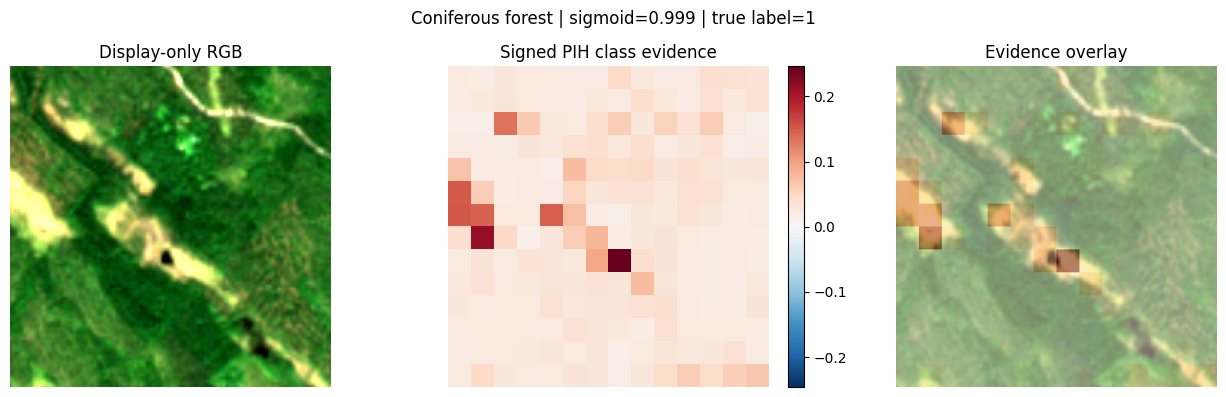

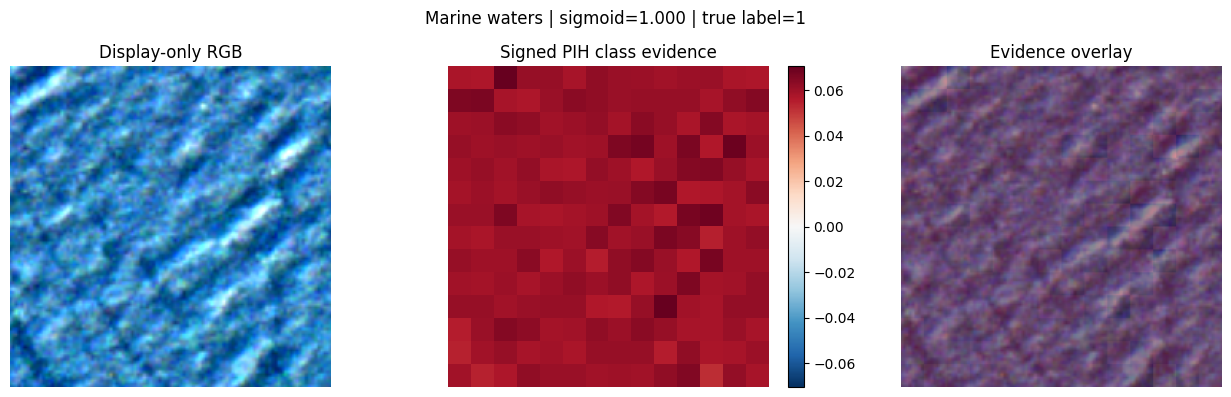

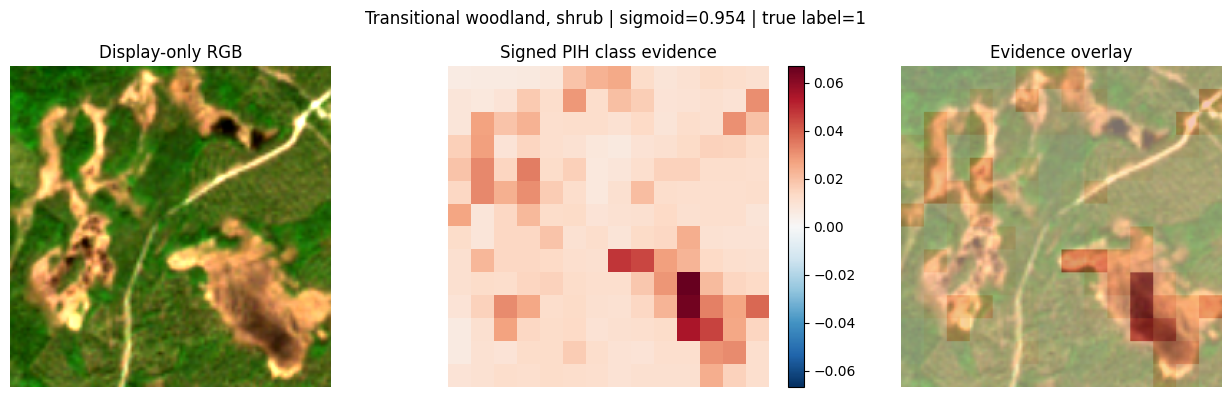

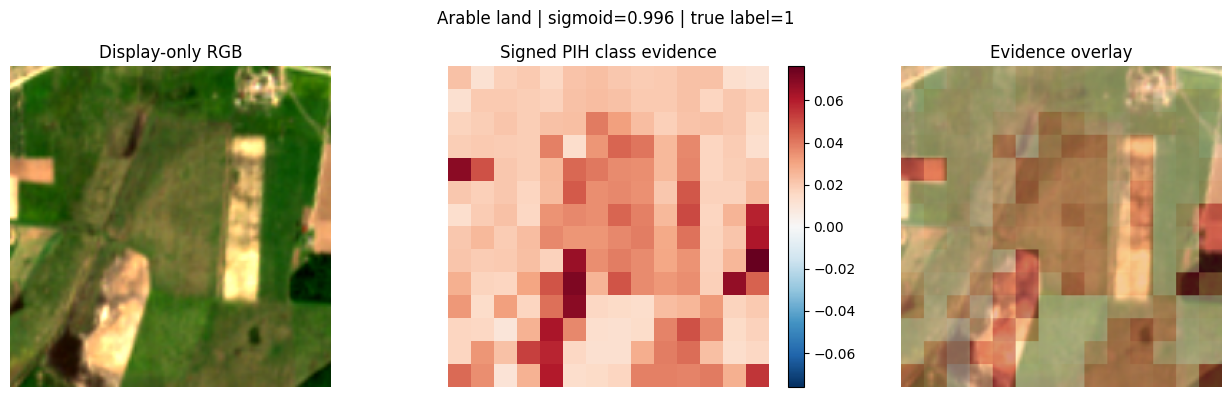

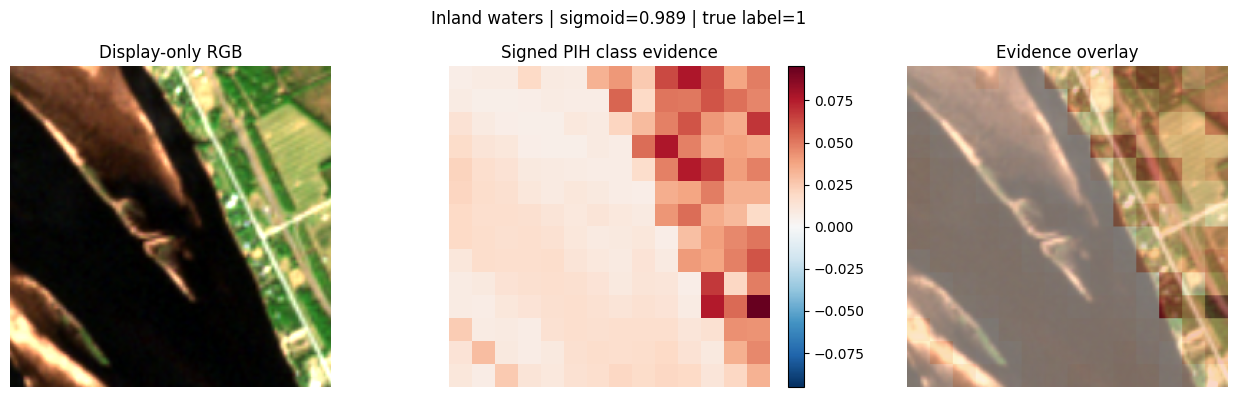

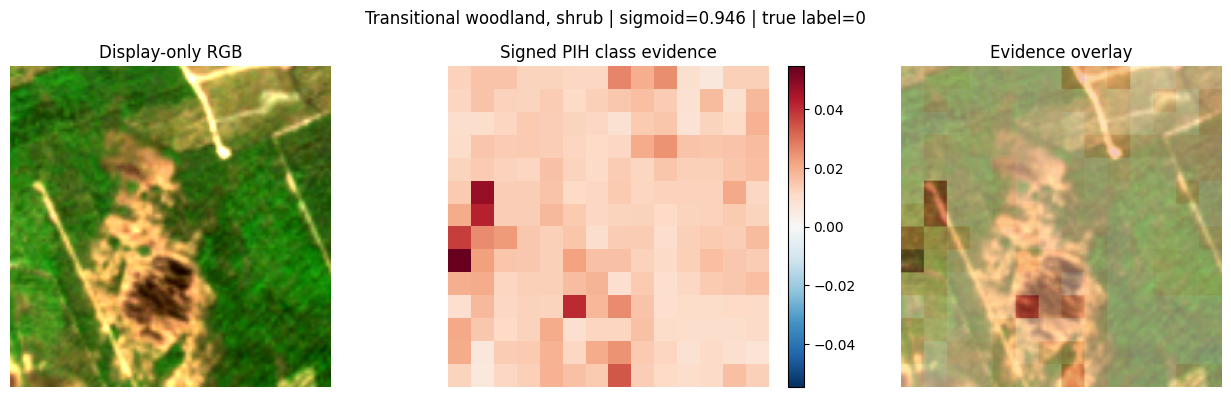

deletion_drop_10                 insertion_gain_10                  \
                    mean       std count              mean       std count   
control                                                                      
bottom          0.004482  0.028776   500          0.249781  0.262413   500   
random          0.003283  0.018954   500          0.459298  0.266099   500   
top             0.021487  0.087638   500          0.247607  0.315486   500   

        deletion_pauc                 insertion_pauc                  \
                 mean       std count           mean       std count   
control                                                                
bottom       0.954810  0.058492   500       0.593767  0.261415   500   
random       0.959506  0.058407   500       0.769115  0.146578   500   
top          0.909055  0.137390   500       0.648788  0.188008   500   

        positive_drop_10                 explanation_seconds                  
                    mean       std count                mean       std count  
control                                                                       
bottom             0.666  0.472112   500            0.084202  0.008355   500  
random             0.732  0.443361   500            0.084202  0.008355   500  
top                0.716  0.451388   500            0.084202  0.008355   500

,metric,comparison,n,mean_advantage,ci95_low,ci95_high,wilcoxon_p,paired_cohens_dz,holm_p
0,deletion_drop_10,top vs random,500,0.018205,0.011438,0.026661,7.292879e-07,0.205225,2.917151e-06
1,deletion_drop_10,top vs bottom,500,0.017005,0.009764,0.025844,8.734876e-06,0.184607,2.620463e-05
2,insertion_gain_10,top vs random,500,-0.211691,-0.241986,-0.182220,4.264121e-30,-0.603905,2.558473e-29
3,insertion_gain_10,top vs bottom,500,-0.002174,-0.035120,0.032950,7.608044e-01,-0.005426,7.608044e-01
4,deletion_pauc,top vs random,500,0.050451,0.041369,0.060407,2.887460e-35,0.450501,2.309968e-34
5,deletion_pauc,top vs bottom,500,0.045755,0.034609,0.057284,1.112372e-14,0.351785,5.561859e-14
6,insertion_pauc,top vs random,500,-0.120327,-0.136518,-0.103989,3.421420e-35,-0.648998,2.394994e-34
7,insertion_pauc,top vs bottom,500,0.055021,0.030823,0.079850,2.999397e-04,0.195525,5.998794e-04


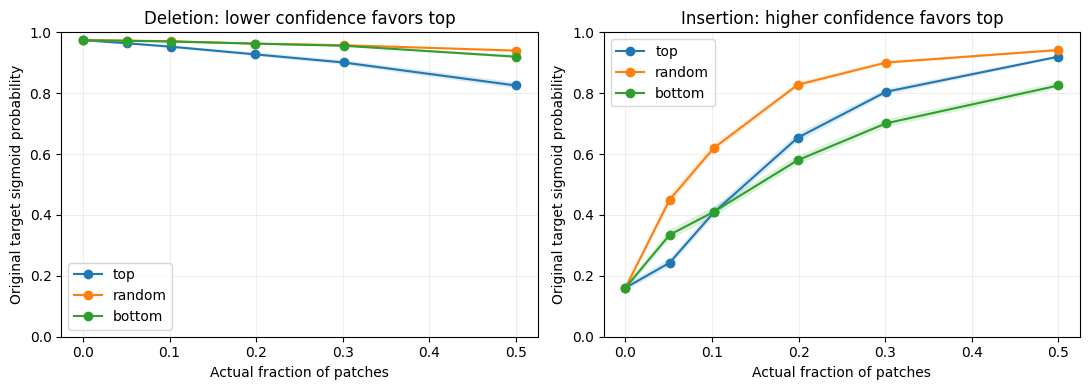

One highest-confidence target class per uniformly sampled test image, fixed before masking.
Sigmoid probabilities; no softmax or target reselection. Signed prototype-class evidence.
Controls mask equal patch counts and use nested orders across fractions.
Zero-reflectance baseline; confidence perturbations can be out of distribution.
pAUC covers only 0 to 0.5, normalized by that interval. Shading is +/-1 image-level SEM.
Paired bootstrap CIs and Wilcoxon tests use images as units, within this single trained seed.
These intervals do not represent variation across training seeds; spatial dependence may narrow them.
Positive mean advantage favors PIH top regions. Check CI and Holm p; negative/uncertain results
must be reported as such. Attractive heatmaps alone do not demonstrate faithfulness.
Results apply only to the available BigEarthNet subset and sampled highest-confidence targets.

PIH evaluation complete: /kaggle/working/PALT_TGRS_results/drive_archives/bigearthnet_training/bigearth

/kaggle/working/PALT_TGRS_results/drive_archives/bigearthnet_training/bigearthnet/BigEarthNet-S2/training/palt/full/seed_13/PIH_faithfulness_500_images.zip

In [25]:
# Run in the SAME Kaggle kernel after the BigEarthNet training notebook definitions.
from pathlib import Path
import json, time, shutil
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from IPython.display import display, FileLink
from tqdm.auto import tqdm

N_IMAGES = 500  # Use 20 for a quick check; keep 500 for the larger evaluation.
SEED = 13
FRACTIONS = [0.05, 0.10, 0.20, 0.30, 0.50]
PERTURB_BATCH = 4
BOOTSTRAPS = 2000
RUN = Path('/kaggle/working/PALT_TGRS_results/drive_archives/bigearthnet_training/bigearthnet/BigEarthNet-S2/training/palt/full/seed_13')
SAVE = RUN / f'PIH_faithfulness_{N_IMAGES}_images'
SAVE.mkdir(parents=True, exist_ok=True)
if 'build_palt' not in globals():
    raise RuntimeError('Run the model and dataset definition cells from the BigEarthNet notebook first. Do not rerun training.')
if 'datasets' not in globals():
    datasets = bigearthnet_splits()  # Reuses downloaded imagery and metadata.
test_ds = datasets[2]
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
checkpoint_path = RUN / 'best.pt'
if not checkpoint_path.is_file():
    raise FileNotFoundError(f'Restore your saved checkpoint here: {checkpoint_path}')
model = build_palt(12, 19, 'multilabel', 'full').to(device).eval()
model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=False)['model'])
threshold_path = RUN / 'threshold.json'
if not threshold_path.exists():
    raise FileNotFoundError('Missing validation-selected threshold.json; restore it from the results ZIP.')
threshold = float(json.loads(threshold_path.read_text())['threshold'])
rng = np.random.default_rng(SEED)
selected = rng.choice(len(test_ds), size=min(N_IMAGES, len(test_ds)), replace=False)
pd.DataFrame({'test_index': selected, 'patch_id': test_ds.ids[selected]}).to_csv(SAVE/'selected_images.csv', index=False)

def sync_gpu():
    if device.type == 'cuda': torch.cuda.synchronize()

def partial_auc(fractions, values):
    fractions, values = np.asarray(fractions), np.asarray(values)
    return float(np.sum(np.diff(fractions)*(values[:-1]+values[1:])/2)/fractions[-1])

@torch.inference_mode()
def evaluate_pih():
    rows, curve_rows = [], []
    for j, idx in enumerate(tqdm(selected, desc='PIH faithfulness: test images')):
        x, y = test_ds[int(idx)]
        x = x.unsqueeze(0).to(device)
        sync_gpu(); started = time.perf_counter()
        out = model(x)
        probabilities = out['logits'].sigmoid()[0]
        # One prespecified target per image prevents correlated class-image pairs
        # from being treated as independent observations in statistical tests.
        target = int(probabilities.argmax())
        original = float(probabilities[target])
        attention = out['attention_map'].mean(1)[0, :, 1:]  # K x spatial tokens; remove CLS.
        importance = out['importance_scores'][0]
        class_evidence = out['prototype_class_scores'][0, :, target]
        evidence = (attention * (importance*class_evidence)[:, None]).sum(0)
        patch = model.cfg.patch_size
        gh, gw = x.shape[-2]//patch, x.shape[-1]//patch
        assert evidence.numel() == gh*gw and torch.isfinite(evidence).all()
        # Fixed zero-reflectance baseline. BigEarthNet inputs were divided by 10,000.
        baseline = torch.zeros_like(x)
        empty = float(model(baseline)['logits'].sigmoid()[0, target])
        orders = {
            'top': evidence.argsort(descending=True),
            'random': torch.tensor(rng.permutation(gh*gw), device=device),
            'bottom': evidence.argsort(),
        }
        start_row = len(rows)
        for control, order in orders.items():
            changed, actual = [], [0.]
            for fraction in FRACTIONS:
                k = max(1, round(gh*gw*fraction))
                mask = torch.zeros(gh*gw, device=device)
                mask[order[:k]] = 1
                mask = mask.reshape(1, 1, gh, gw).repeat_interleave(patch, -2).repeat_interleave(patch, -1)
                changed.extend([x*(1-mask), x*mask])
                actual.append(k/(gh*gw))
            changed = torch.cat(changed)
            values = torch.cat([model(b)['logits'].sigmoid()[:, target]
                                for b in changed.split(PERTURB_BATCH)]).cpu().numpy()
            deletion = [original, *values[0::2].tolist()]
            insertion = [empty, *values[1::2].tolist()]
            for t, f in enumerate([0., *FRACTIONS]):
                curve_rows.append(dict(patch_id=str(test_ds.ids[idx]), target=target,
                    control=control, fraction=f, actual_fraction=actual[t],
                    deletion_confidence=deletion[t], insertion_confidence=insertion[t],
                    deletion_drop=original-deletion[t], insertion_gain=insertion[t]-empty))
            rows.append(dict(patch_id=str(test_ds.ids[idx]), target=target,
                target_name=test_ds.classes[target], target_is_true=int(y[target]),
                target_above_threshold=int(original>=threshold), control=control,
                original_confidence=original, baseline_confidence=empty,
                deletion_drop_10=original-deletion[2], insertion_gain_10=insertion[2]-empty,
                deletion_pauc=partial_auc(actual, deletion), insertion_pauc=partial_auc(actual, insertion),
                positive_drop_10=int(original>deletion[2])))
        sync_gpu(); elapsed = time.perf_counter()-started
        for r in rows[start_row:]: r['explanation_seconds'] = elapsed
        if j < 6:
            rgb = x[0,[3,2,1]].permute(1,2,0).cpu().numpy()
            lo, hi = np.percentile(rgb, [2,98]); rgb = np.clip((rgb-lo)/(hi-lo+1e-8), 0, 1)
            heat = evidence.reshape(gh,gw).cpu().numpy()
            full_heat = torch.nn.functional.interpolate(evidence.reshape(1,1,gh,gw),size=x.shape[-2:],mode='nearest')[0,0].cpu().numpy()
            lim = max(float(np.abs(heat).max()),1e-8)
            fig, ax = plt.subplots(1,3,figsize=(13,4))
            ax[0].imshow(rgb); ax[0].set_title('Display-only RGB')
            im = ax[1].imshow(heat,cmap='RdBu_r',vmin=-lim,vmax=lim); ax[1].set_title('Signed PIH class evidence')
            ax[2].imshow(rgb); ax[2].imshow(full_heat,cmap='RdBu_r',vmin=-lim,vmax=lim,alpha=.5); ax[2].set_title('Evidence overlay')
            for a in ax: a.axis('off')
            fig.colorbar(im,ax=ax[1],fraction=.046)
            fig.suptitle(f'{test_ds.classes[target]} | sigmoid={original:.3f} | true label={int(y[target])}')
            fig.tight_layout(); fig.savefig(SAVE/f'example_{j+1}.png',dpi=160,bbox_inches='tight')
            display(fig); plt.close(fig)
        if (j+1)%25 == 0:
            pd.DataFrame(rows).to_csv(SAVE/'per_image_partial.csv',index=False)
    return pd.DataFrame(rows), pd.DataFrame(curve_rows)

raw, curves = evaluate_pih()
raw.to_csv(SAVE/'per_image.csv',index=False)
curves.to_csv(SAVE/'curves_per_image.csv',index=False)
metrics = ['deletion_drop_10','insertion_gain_10','deletion_pauc','insertion_pauc','positive_drop_10','explanation_seconds']
summary = raw.groupby('control')[metrics].agg(['mean','std','count'])
summary.to_csv(SAVE/'faithfulness_summary.csv')
raw.groupby(['target_name','control'])[metrics].agg(['mean','count']).to_csv(SAVE/'class_wise.csv')
display(summary)

# Paired unit = image. Positive advantage always favors top-ranked PIH evidence.
stats_rows = []
bootstrap_rng = np.random.default_rng(SEED+1)
for metric, sign in [('deletion_drop_10',1),('insertion_gain_10',1),('deletion_pauc',-1),('insertion_pauc',1)]:
    paired = raw.pivot(index='patch_id',columns='control',values=metric)
    for control in ['random','bottom']:
        difference = sign*(paired['top']-paired[control]).to_numpy()
        boot = np.array([bootstrap_rng.choice(difference,len(difference),replace=True).mean() for _ in range(BOOTSTRAPS)])
        sd = difference.std(ddof=1)
        p = 1. if np.all(difference==0) else float(wilcoxon(difference,alternative='two-sided').pvalue)
        stats_rows.append(dict(metric=metric,comparison='top vs '+control,n=len(difference),
            mean_advantage=difference.mean(),ci95_low=np.quantile(boot,.025),ci95_high=np.quantile(boot,.975),
            wilcoxon_p=p,paired_cohens_dz=difference.mean()/sd if sd>0 else np.nan))
tests = pd.DataFrame(stats_rows)
order = np.argsort(tests.wilcoxon_p.to_numpy())
adjusted = np.minimum(1,np.maximum.accumulate(tests.wilcoxon_p.to_numpy()[order]*(len(order)-np.arange(len(order)))))
tests.loc[order,'holm_p'] = adjusted
tests.to_csv(SAVE/'paired_statistics.csv',index=False); display(tests)

fig, axes = plt.subplots(1,2,figsize=(11,4))
for control in ['top','random','bottom']:
    group = curves[curves.control==control].groupby('actual_fraction')
    for ax, metric in zip(axes,['deletion_confidence','insertion_confidence']):
        avg = group[metric].mean(); error = group[metric].sem().fillna(0)
        ax.plot(avg.index,avg.values,marker='o',label=control)
        ax.fill_between(avg.index,(avg-error).values,(avg+error).values,alpha=.15)
axes[0].set_title('Deletion: lower confidence favors top')
axes[1].set_title('Insertion: higher confidence favors top')
for ax in axes:
    ax.set(xlabel='Actual fraction of patches',ylabel='Original target sigmoid probability',ylim=(0,1)); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(SAVE/'deletion_insertion_curves.png',dpi=180); display(fig); plt.close(fig)

notes = '''One highest-confidence target class per uniformly sampled test image, fixed before masking.
Sigmoid probabilities; no softmax or target reselection. Signed prototype-class evidence.
Controls mask equal patch counts and use nested orders across fractions.
Zero-reflectance baseline; confidence perturbations can be out of distribution.
pAUC covers only 0 to 0.5, normalized by that interval. Shading is +/-1 image-level SEM.
Paired bootstrap CIs and Wilcoxon tests use images as units, within this single trained seed.
These intervals do not represent variation across training seeds; spatial dependence may narrow them.
Positive mean advantage favors PIH top regions. Check CI and Holm p; negative/uncertain results
must be reported as such. Attractive heatmaps alone do not demonstrate faithfulness.
Results apply only to the available BigEarthNet subset and sampled highest-confidence targets.
'''
(SAVE/'README.txt').write_text(notes)
(SAVE/'configuration.json').write_text(json.dumps(dict(seed=SEED,n_images=len(selected),checkpoint=str(checkpoint_path),
    threshold=threshold,masking_fractions=FRACTIONS,target_rule='highest sigmoid per image',baseline='zero reflectance'),indent=2))
zip_path = shutil.make_archive(str(SAVE),'zip',root_dir=SAVE)
print(notes)
print('PIH evaluation complete:',SAVE)
print('Download ZIP from Kaggle Output/Files:',zip_path)
display(FileLink(zip_path))


In [ ]:
from pathlib import Path
import json, time, shutil
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from tqdm.auto import tqdm
from IPython.display import display, FileLink

# ---------- Settings ----------
N_IMAGES = 20
SEED = 13
FRACTIONS = [0.05, 0.10, 0.20, 0.30, 0.50]

RUN = (
    OUT / "BigEarthNet-S2" / "training"
    / "palt" / "full" / "seed_13"
)
SAVE = RUN / f"PIH_{N_IMAGES}_images"
SAVE.mkdir(parents=True, exist_ok=True)

# Existing notebook definitions must already be loaded.
if "datasets" not in globals():
    datasets = bigearthnet_splits()

test_ds = datasets[2]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = build_palt(12, 19, "multilabel", "full").to(device).eval()
checkpoint = torch.load(
    RUN / "best.pt", map_location=device, weights_only=False
)
model.load_state_dict(checkpoint["model"])

threshold = float(
    json.loads((RUN / "threshold.json").read_text())["threshold"]
)

rng = np.random.default_rng(SEED)
selected = rng.choice(
    len(test_ds), min(N_IMAGES, len(test_ds)), replace=False
)

pd.DataFrame({
    "test_index": selected,
    "patch_id": test_ds.ids[selected],
}).to_csv(SAVE / "selected_images.csv", index=False)

print("Checkpoint loaded. Device:", device)
print("Test images:", len(selected))
print("Target: highest-confidence class per image.")
print("Baseline: zero reflectance. No retraining.")


def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()


def partial_auc(fractions, values):
    f, v = np.asarray(fractions), np.asarray(values)
    return float(
        np.sum(np.diff(f) * (v[:-1] + v[1:]) / 2) / f[-1]
    )


@torch.inference_mode()
def run_pih():
    rows, curves = [], []

    for number, index in enumerate(
        tqdm(selected, desc="PIH faithfulness")
    ):
        x, labels = test_ds[int(index)]
        x = x.unsqueeze(0).to(device)

        synchronize()
        started = time.perf_counter()

        output = model(x)
        probabilities = output["logits"].sigmoid()[0]

        # Fix the target before masking; never reselect it.
        target = int(probabilities.argmax())
        original = float(probabilities[target])

        # Prototype-token attention × sample importance
        # × signed evidence for this target class.
        attention = output["attention_map"].mean(1)[0, :, 1:]
        importance = output["importance_scores"][0]
        class_evidence = output["prototype_class_scores"][0, :, target]

        evidence = (
            attention * (importance * class_evidence)[:, None]
        ).sum(0)

        patch_size = model.cfg.patch_size
        gh = x.shape[-2] // patch_size
        gw = x.shape[-1] // patch_size
        tokens = gh * gw

        assert evidence.numel() == tokens
        assert torch.isfinite(evidence).all()

        empty_confidence = float(
            model(torch.zeros_like(x))["logits"].sigmoid()[0, target]
        )

        orders = {
            "top": evidence.argsort(descending=True),
            "random": torch.tensor(
                rng.permutation(tokens), device=device
            ),
            "bottom": evidence.argsort(),
        }

        image_rows = []

        for control, order in orders.items():
            changed_images = []
            actual_fractions = [0.0]

            for fraction in FRACTIONS:
                k = max(1, round(tokens * fraction))
                mask = torch.zeros(tokens, device=device)
                mask[order[:k]] = 1

                mask = mask.reshape(1, 1, gh, gw)
                mask = mask.repeat_interleave(
                    patch_size, -2
                ).repeat_interleave(patch_size, -1)

                # Equal-size masks for all three controls.
                changed_images.extend([
                    x * (1 - mask),  # Deletion
                    x * mask,        # Insertion from zero baseline
                ])
                actual_fractions.append(k / tokens)

            changed_images = torch.cat(changed_images)

            # Small perturbation batches keep GPU memory manageable.
            values = torch.cat([
                model(batch)["logits"].sigmoid()[:, target]
                for batch in changed_images.split(4)
            ]).cpu().numpy()

            deletion = [original, *values[0::2].tolist()]
            insertion = [empty_confidence, *values[1::2].tolist()]

            for j, fraction in enumerate([0.0, *FRACTIONS]):
                curves.append({
                    "patch_id": str(test_ds.ids[index]),
                    "target": target,
                    "control": control,
                    "fraction": fraction,
                    "actual_fraction": actual_fractions[j],
                    "deletion_confidence": deletion[j],
                    "insertion_confidence": insertion[j],
                    "deletion_drop": original - deletion[j],
                    "insertion_gain": insertion[j] - empty_confidence,
                })

            image_rows.append({
                "patch_id": str(test_ds.ids[index]),
                "target": target,
                "target_name": test_ds.classes[target],
                "target_is_true": int(labels[target]),
                "target_above_threshold": int(original >= threshold),
                "control": control,
                "original_confidence": original,
                "baseline_confidence": empty_confidence,
                # Index 2 corresponds to requested fraction 0.10.
                "deletion_drop_10": original - deletion[2],
                "insertion_gain_10": insertion[2] - empty_confidence,
                "deletion_pauc": partial_auc(
                    actual_fractions, deletion
                ),
                "insertion_pauc": partial_auc(
                    actual_fractions, insertion
                ),
                "positive_drop_10": int(original > deletion[2]),
            })

        synchronize()
        elapsed = time.perf_counter() - started
        for row in image_rows:
            row["explanation_seconds"] = elapsed
        rows.extend(image_rows)

        # Save and display six explanation examples.
        if number < 6:
            rgb = x[0, [3, 2, 1]].permute(1, 2, 0).cpu().numpy()
            lo, hi = np.percentile(rgb, [2, 98])
            rgb = np.clip((rgb - lo) / (hi - lo + 1e-8), 0, 1)

            heat = evidence.reshape(gh, gw).cpu().numpy()
            full_heat = torch.nn.functional.interpolate(
                evidence.reshape(1, 1, gh, gw),
                size=x.shape[-2:],
                mode="nearest",
            )[0, 0].cpu().numpy()

            limit = max(float(np.abs(heat).max()), 1e-8)
            fig, axes = plt.subplots(1, 3, figsize=(13, 4))

            axes[0].imshow(rgb)
            axes[0].set_title("Display-only RGB")

            im = axes[1].imshow(
                heat, cmap="RdBu_r", vmin=-limit, vmax=limit
            )
            axes[1].set_title("Signed PIH evidence")

            axes[2].imshow(rgb)
            axes[2].imshow(
                full_heat, cmap="RdBu_r",
                vmin=-limit, vmax=limit, alpha=0.5
            )
            axes[2].set_title("PIH overlay")

            for ax in axes:
                ax.axis("off")

            fig.colorbar(im, ax=axes[1], fraction=0.046)
            fig.suptitle(
                f"{test_ds.classes[target]} | "
                f"confidence={original:.3f} | "
                f"true label={int(labels[target])}"
            )
            fig.tight_layout()
            fig.savefig(
                SAVE / f"example_{number + 1}.png",
                dpi=160, bbox_inches="tight"
            )
            display(fig)
            plt.close(fig)

        if (number + 1) % 25 == 0:
            pd.DataFrame(rows).to_csv(
                SAVE / "per_image_partial.csv", index=False
            )

    return pd.DataFrame(rows), pd.DataFrame(curves)


# ---------- Run evaluation ----------
raw, curves = run_pih()
raw.to_csv(SAVE / "per_image.csv", index=False)
curves.to_csv(SAVE / "curves_per_image.csv", index=False)

metrics = [
    "deletion_drop_10",
    "insertion_gain_10",
    "deletion_pauc",
    "insertion_pauc",
    "positive_drop_10",
    "explanation_seconds",
]

summary = raw.groupby("control")[metrics].agg(["mean", "std", "count"])
summary.to_csv(SAVE / "faithfulness_summary.csv")

raw.groupby(["target_name", "control"])[metrics].agg(
    ["mean", "count"]
).to_csv(SAVE / "class_wise.csv")

print("\nFAITHFULNESS SUMMARY")
display(summary)

# ---------- Paired statistical comparisons ----------
# One observation per image.
# Positive advantage always means top performs better.
stat_rows = []
bootstrap_rng = np.random.default_rng(SEED + 1)

for metric, sign in [
    ("deletion_drop_10", 1),
    ("insertion_gain_10", 1),
    ("deletion_pauc", -1),  # Lower deletion confidence AUC is better.
    ("insertion_pauc", 1),
]:
    paired = raw.pivot(
        index="patch_id", columns="control", values=metric
    )

    for control in ["random", "bottom"]:
        difference = (
            sign * (paired["top"] - paired[control])
        ).to_numpy()

        bootstrap_means = np.array([
            bootstrap_rng.choice(
                difference, len(difference), replace=True
            ).mean()
            for _ in range(2000)
        ])

        sd = difference.std(ddof=1)
        p = (
            1.0 if np.all(difference == 0)
            else float(wilcoxon(
                difference, alternative="two-sided"
            ).pvalue)
        )

        stat_rows.append({
            "metric": metric,
            "comparison": f"top vs {control}",
            "n": len(difference),
            "mean_advantage": difference.mean(),
            "ci95_low": np.quantile(bootstrap_means, 0.025),
            "ci95_high": np.quantile(bootstrap_means, 0.975),
            "wilcoxon_p": p,
            "paired_cohens_dz": (
                difference.mean() / sd if sd > 0 else np.nan
            ),
        })

tests = pd.DataFrame(stat_rows)

# Holm correction across the eight comparisons.
order = np.argsort(tests["wilcoxon_p"].to_numpy())
adjusted = np.minimum(
    1,
    np.maximum.accumulate(
        tests["wilcoxon_p"].to_numpy()[order]
        * (len(order) - np.arange(len(order)))
    ),
)
tests.loc[order, "holm_p"] = adjusted
tests.to_csv(SAVE / "paired_statistics.csv", index=False)

print("\nPAIRED STATISTICAL TESTS")
display(tests)

# ---------- Deletion / insertion figures ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for control in ["top", "random", "bottom"]:
    grouped = curves[curves.control == control].groupby(
        "actual_fraction"
    )

    for ax, metric in zip(
        axes, ["deletion_confidence", "insertion_confidence"]
    ):
        mean = grouped[metric].mean()
        sem = grouped[metric].sem().fillna(0)

        ax.plot(mean.index, mean.values, marker="o", label=control)
        ax.fill_between(
            mean.index,
            (mean - sem).values,
            (mean + sem).values,
            alpha=0.15,
        )

axes[0].set_title("Deletion: lower confidence favors top")
axes[1].set_title("Insertion: higher confidence favors top")

for ax in axes:
    ax.set(
        xlabel="Actual fraction of patches",
        ylabel="Original target sigmoid probability",
        ylim=(0, 1),
    )
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(SAVE / "deletion_insertion_curves.png", dpi=180)
display(fig)
plt.close(fig)

# ---------- Save interpretation notes and download ----------
notes = """
One highest-confidence class is explained per sampled test image.
The target remains fixed for every perturbation. Probabilities use sigmoid.
Top/random/bottom masks contain equal numbers of patches.
Baseline: zero reflectance; masking may create out-of-distribution inputs.
Partial AUC covers 0 to 0.5 and is normalized by that interval.
Curve shading is +/-1 image-level standard error.
Positive mean_advantage favors PIH top regions.
Confidence intervals and tests describe sampled images for this one model,
not variation across training seeds. Spatial dependence is not modeled.
Results apply to the available BigEarthNet subset, not the full benchmark.
Heatmaps alone do not establish faithfulness.
"""
(SAVE / "README.txt").write_text(notes)

(SAVE / "configuration.json").write_text(json.dumps({
    "seed": SEED,
    "n_images": len(selected),
    "checkpoint": str(RUN / "best.pt"),
    "threshold": threshold,
    "fractions": FRACTIONS,
    "target_rule": "highest-confidence class per image",
    "baseline": "zero reflectance",
}, indent=2))

zip_path = shutil.make_archive(str(SAVE), "zip", root_dir=str(SAVE))

print("\nPIH evaluation completed.")
print("Results:", SAVE)
print("Download ZIP from Kaggle Output/Files:", zip_path)
display(FileLink(zip_path))

## Validation before delivery
Executed locally: notebook JSON/structure checks, compilation of every Python cell, AST comparison confirming unchanged PALT/PIH architecture, and synthetic ZIP extraction/reuse/path-traversal tests for the archive utility. Synthetic v1/v2 label mapping checks were also executed.

Not executed: downloads of your Drive datasets, raster decoding, model forward tests, GPU training, or Kaggle end-to-end execution. The Drive archive contents were unavailable for inspection. Runtime data checks and synthetic model tests are included; no training metrics are fabricated.
